<a href="https://colab.research.google.com/github/urnnatipragyan/DMPM-Lab/blob/main/DMPM_LAB_EXP_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cluster Labels:
[0 0 0 1 1 1]

Cluster Centers:
[[ 3.          3.33333333]
 [11.         11.33333333]]


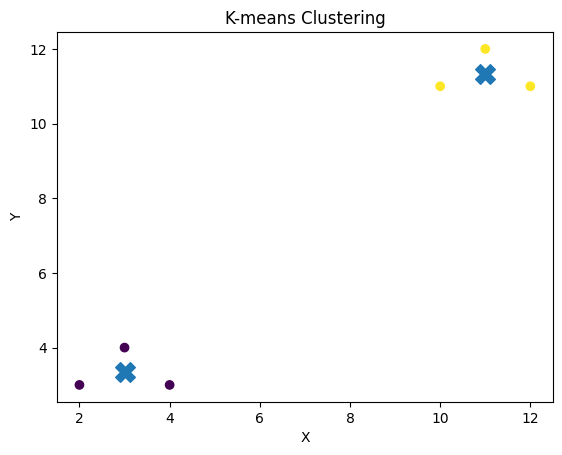

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
# sample data
X = np.array([
    [2,3],
    [3,4],
    [4,3],
    [10,11],
    [11,12],
    [12,11]
    ])
# Apply K-means
kmeans =KMeans(n_clusters=2, random_state=42,n_init=10)
labels = kmeans.fit_predict(X)
# Display cluster information
print("Cluster Labels:")
print(labels)
# Display cluster centers
print("\nCluster Centers:")
print(kmeans.cluster_centers_)
# Plot Clusters
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],  marker='X', s=200)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('K-means Clustering')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
X = np.array([
    [2,3,],
    [3,4],
    [4,3],
    [10,11],
    [11,12],
    [12,11]
])
k=2
medoid_indices=[0,3]
while True:
  distances = np.zeros((len(X), k))
  for i in range(len(X)):
    for j in range(k):
      distances[i,j]=np.linalg.norm(X[i]-X[medoid_indices[j]])
  labels = np.argmin(distances, axis=1)
  new_medoid_indices = []
  for cluster in range(k):
    cluster_indices = np.where(labels == cluster)[0]
    if len(cluster_indices) == 0:
      new_medoid_indices.append(medoid_indices[cluster])
      continue
    total_distances=[]
    for i in cluster_indices:
      total = 0
      for j in cluster_indices:
          total += np.linalg.norm(X[i]-X[j])
      total_distances.append(total)
    new_medoid = cluster_indices[np.argmin(total_distances)]
    new_medoid_indices.append(new_medoid)
  if new_medoid_indices == medoid_indices:
    break
    medoid_indices = new_medoid_indices
print("Cluster Labels:")
print(labels)
print("\nMediod point:")
for index in medoid_indices:
  print(X[index])
plt.scatter(X[:,0],X[:,1],c=labels)
medoids = X[medoid_indices]
plt.scatter(medoids[:,0],medoids[:,1],marker='X',s =200)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("K-medoids Clustering")
plt.show()